# 03 · K-Nearest Neighbors (California Housing)

**Input:** `../data/processed/california_housing_clean.csv` · **Target:** `MedHouseVal` (regression, ឯកតា $100,000)

## 1. Goal
ទាយតម្លៃផ្ទះរបស់សង្កាត់មួយ ដោយមើលតម្លៃរបស់ **សង្កាត់ជិតខាងដែលស្រដៀងគ្នាបំផុត** ក្នុង training data។ KNN ជា model ដែលសាមញ្ញបំផុតក្នុងការយល់
ហើយបង្ហាញយ៉ាងច្បាស់ពី **ហេតុអ្វី scaling សំខាន់** សម្រាប់ models ដែលផ្អែកលើ distance។

## Concept
1. ដើម្បីទាយសង្កាត់ថ្មីមួយ គណនា **distance** ទៅគ្រប់ training rows (Euclidean distance លើ features ទាំងអស់)។
2. រើស `k` rows ដែលនៅជិតបំផុត។
3. **Regression:** ទាយ **មធ្យម** នៃ `MedHouseVal` របស់ `k` rows នោះ (Classification ក្នុង Titanic ប្រើការបោះឆ្នោតភាគច្រើន)។

**ឧបមា "សួរអ្នកជិតខាង":** ចង់ដឹងតម្លៃផ្ទះរបស់អ្នក? សួរម្ចាស់ផ្ទះ 10 នាក់ដែលផ្ទះស្រដៀងគ្នាបំផុត (ចំណូល, ទីតាំង, ទំហំ) ហើយយកមធ្យម។
KNN **មិនរៀន** weights ទេ។ វា **ទន្ទេញ** training data ហើយគណនាពេលទាយ (lazy learner)។ `k` តូច = ស្តាប់មនុស្សតិចនាក់ (រវើរវាយ, ងាយ overfit);
`k` ធំ = សួរមនុស្សច្រើនពេក (រលោងពេក, underfit)។

Import libraries។

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"

def style(ax):
    """Light grid, no top/right spines."""
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)

def evaluate(model, A, B):
    """Train and test MAE / RMSE / R2 for a fitted model. A = train features, B = test features."""
    out = {}
    for split, Xs, ys in [("train", A, y_train), ("test", B, y_test)]:
        pred = model.predict(Xs)
        out[f"{split} MAE"] = mean_absolute_error(ys, pred)
        out[f"{split} RMSE"] = np.sqrt(mean_squared_error(ys, pred))
        out[f"{split} R2"] = r2_score(ys, pred)
    return out

Load clean data ហើយ split ដូច Lesson 2 (`test_size=0.2`, `random_state=42`)។ បន្ទាប់មក scale ដោយ `StandardScaler` ដែល fit លើ **train តែប៉ុណ្ណោះ**។

In [2]:
df = pd.read_csv("../data/processed/california_housing_clean.csv")
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit + transform on train
X_test_s = scaler.transform(X_test)         # transform ONLY on test
X_train.shape, X_test.shape

((15546, 8), (3887, 8))

## 2. Why scaling matters
KNN គណនា distance លើ features ទាំងអស់ **ដោយបូកចូលគ្នា**។ បើ feature មួយមានតម្លៃធំ វា "ស្រែកខ្លាំងជាង" ហើយ features តូចៗត្រូវបានគេមិនអើពើ។
មើល standard deviation នៃ feature នីមួយៗ មុន scaling:

In [3]:
X_train.std().round(2).to_frame("std (unscaled)").T

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
std (unscaled),1.57,12.48,1.27,0.16,1103.45,0.72,2.15,2.01


`Population` មាន std ≈ 1,100 ចំណែក `MedInc` ≈ 1.6 និង `AveBedrms` ≈ 0.16។ បើមិន scale ទេ distance ស្ទើរតែអាស្រ័យលើ `Population` តែមួយ។
ប្រៀបធៀប KNN (`k=10`) ដែលមិន scale ទល់នឹង scale។

In [4]:
knn_unscaled = KNeighborsRegressor(n_neighbors=10).fit(X_train, y_train)
knn_scaled = KNeighborsRegressor(n_neighbors=10).fit(X_train_s, y_train)
pd.DataFrame({
    "unscaled": evaluate(knn_unscaled, X_train, X_test),
    "scaled": evaluate(knn_scaled, X_train_s, X_test_s),
}).T.round(3)

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
unscaled,0.659,0.834,0.262,0.733,0.926,0.104
scaled,0.341,0.482,0.753,0.380,0.536,0.700


**អានលទ្ធផល:** Scaling ផ្លាស់ប្តូរអ្វីៗទាំងអស់។ Test R² លោតពី **0.104** (មិន scale) ទៅ **0.700** (scale) ហើយ test MAE ធ្លាក់ពី 0.733 ទៅ 0.380។
ដោយមិន scale, model ស្ទើរតែមើលតែ `Population` (ដែលមាន std ធំបំផុត) ហើយមិនអើពើនឹង `MedInc` និងទីតាំងដែលសំខាន់បំផុតទេ។ (សូម្បីតែ train R² ក៏ត្រឹមតែ 0.26 ដែរ ដែលមានន័យថា model មិនអាច fit data របស់ខ្លួនបានល្អ។) **KNN តែងតែត្រូវការ scaling។**

## 3. Effect of k
សាកល្បង `k` ច្រើនតម្លៃ លើ data ដែល scale រួច ហើយប្រៀបធៀប train និង test **RMSE** (ទាបជាង = ល្អជាង)។

In [5]:
rows = []
for k in [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100]:
    m = KNeighborsRegressor(n_neighbors=k).fit(X_train_s, y_train)
    r = evaluate(m, X_train_s, X_test_s)
    rows.append({"k": k, "train RMSE": r["train RMSE"], "test RMSE": r["test RMSE"], "test R2": r["test R2"]})
k_results = pd.DataFrame(rows).set_index("k")
k_results.round(4).T

k,1,2,3,5,7,10,15,20,30,50,75,100
train RMSE,0.0000,0.3454,0.4009,0.4437,0.4637,0.4823,0.4984,0.5078,0.5202,0.5367,0.5491,0.5587
test RMSE,0.6969,0.6078,0.5693,0.5484,0.5363,0.5358,0.5350,0.5368,0.5392,0.5479,0.5582,0.5664
test R2,0.4929,0.6144,0.6617,0.6861,0.6997,0.7003,0.7012,0.6991,0.6965,0.6866,0.6747,0.6650


Plot train ទល់នឹង test RMSE។

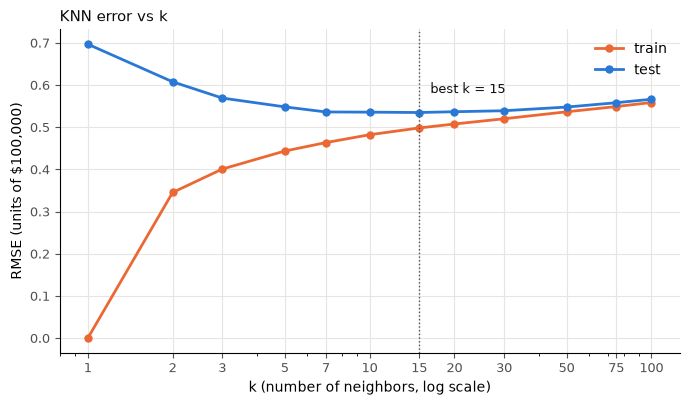

15

In [6]:
best_k = int(k_results["test RMSE"].idxmin())

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(k_results.index, k_results["train RMSE"], color=ORANGE, linewidth=2, marker="o", markersize=5, label="train")
ax.plot(k_results.index, k_results["test RMSE"], color=BLUE, linewidth=2, marker="o", markersize=5, label="test")
ax.axvline(best_k, color=MUTED, linewidth=1, linestyle=":")
ax.annotate(f"best k = {best_k}", (best_k, k_results["test RMSE"].min()), xytext=(8, 14),
            textcoords="offset points", color=INK, fontsize=9)
ax.set_xscale("log"); ax.set_xticks(k_results.index); ax.set_xticklabels(k_results.index)
ax.set_xlabel("k (number of neighbors, log scale)"); ax.set_ylabel("RMSE (units of $100,000)")
ax.set_title("KNN error vs k", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False); style(ax)
plt.show()
best_k

**អានក្រាហ្វ:**
- **k = 1:** train RMSE = 0 (ទន្ទេញ) ប៉ុន្តែ test RMSE ខ្ពស់បំផុត (0.697): Overfitting ខ្លាំង ព្រោះតម្លៃទាយអាស្រ័យលើអ្នកជិតខាងតែម្នាក់ដែលអាចជា noise។
- **k កាន់តែធំ:** train RMSE កើនឡើង (model រលោងជាង ទន្ទេញតិចជាង) ហើយ test RMSE ធ្លាក់ចុះរហូតដល់ **k = 15** (0.535, R² 0.701) រួចចាប់ផ្តើមកើនឡើងម្តងទៀត។
- **k ធំខ្លាំង (50–100):** train និង test ជិតគ្នា ហើយទាំងពីរកើនឡើង: **Underfitting** (មធ្យមនៃសង្កាត់ឆ្ងាយៗ លែងពិតតាមតំបន់)។
- តំបន់ k = 7 ដល់ 30 រាបស្មើ (test RMSE 0.535–0.539) ដូច្នេះ k = 10 ឬ 15 គឺស្ទើរតែល្អស្មើគ្នា។

⚠️ **ការព្រមាន (leakage ស្រាល):** យើងជ្រើស `k` ដោយមើល **test RMSE** ដូច្នេះ test score របស់ k ដែលល្អបំផុតគឺសុទិដ្ឋិនិយមបន្តិច។
វិធីត្រឹមត្រូវ: ជ្រើស hyperparameters ដោយ **Cross-Validation លើ train តែប៉ុណ្ណោះ** → Lesson 8។ (ដោយសារខ្សែកោងរាបស្មើ ផលប៉ះពាល់ត្រង់នេះតូច។)

## 4. Final model
ប្រើ `k = best_k` ពីខាងលើ។ សាកល្បងផងដែរ `weights="distance"` (អ្នកជិតខាងកាន់តែជិត ទទួលសម្លេងកាន់តែខ្លាំង) ជំនួស `"uniform"` (សម្លេងស្មើគ្នា)។

In [7]:
knn = KNeighborsRegressor(n_neighbors=best_k).fit(X_train_s, y_train)
knn_dist = KNeighborsRegressor(n_neighbors=best_k, weights="distance").fit(X_train_s, y_train)
pd.DataFrame({
    f"KNN (k={best_k}, uniform)": evaluate(knn, X_train_s, X_test_s),
    f"KNN (k={best_k}, distance)": evaluate(knn_dist, X_train_s, X_test_s),
}).T.round(3)

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
"KNN (k=15, uniform)",0.354,0.498,0.737,0.380,0.535,0.701
"KNN (k=15, distance)",0.000,0.000,1.000,0.376,0.531,0.705


**អានលទ្ធផល:** KNN (`k=15`, uniform): **test MAE 0.380, RMSE 0.535, R² 0.701**។ Train R² 0.737 ជិត test ដូច្នេះមិន overfit ខ្លាំងទេ។

`weights="distance"` ល្អជាងបន្តិចលើ test (RMSE 0.531, R² 0.705) ប៉ុន្តែ **train R² = 1.000**។ មូលហេតុ: ក្នុង training set row ម្នាក់ៗមានអ្នកជិតខាងជិតបំផុតគឺ **ខ្លួនវាផ្ទាល់** (distance 0)
ហើយ `weights="distance"` ឲ្យសម្លេងធំគ្មានកំណត់ទៅ distance 0 → ទាយបានត្រឹមត្រូវទាំងស្រុង។ ដូច្នេះ train score នេះ **គ្មានន័យ** (វាមិនបង្ហាញថា model ល្អទេ)។ ភាពខុសគ្នា test (0.004 R²) តូចពេកក្នុងការសន្និដ្ឋាន។
យើងប្រើ `uniform` ជា model ចម្បង ព្រោះ train score របស់វាអាចប្រៀបធៀបបាន។

Residual plot និង predicted vs actual សម្រាប់ KNN (`uniform`)។

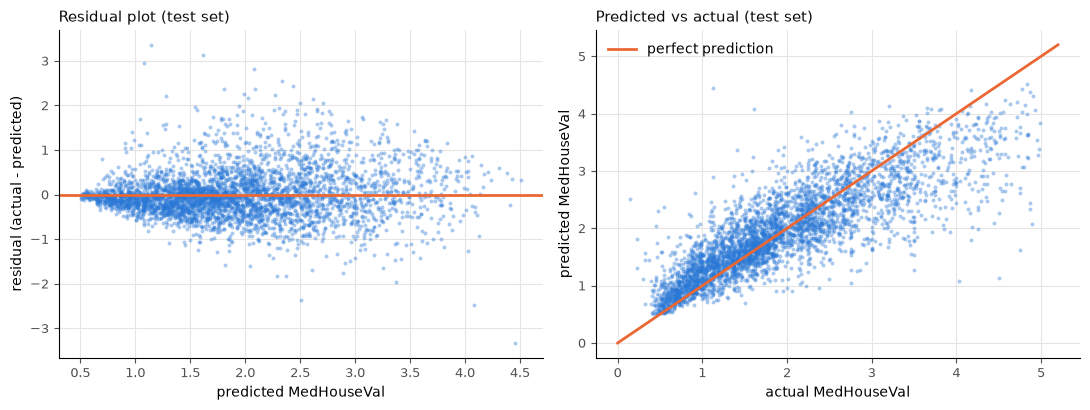

In [8]:
pred_test = knn.predict(X_test_s)
resid = y_test - pred_test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.scatter(pred_test, resid, s=8, color=BLUE, alpha=0.4, linewidth=0)
ax1.axhline(0, color=ORANGE, linewidth=2)
ax1.set_xlabel("predicted MedHouseVal"); ax1.set_ylabel("residual (actual - predicted)")
ax1.set_title("Residual plot (test set)", loc="left", fontsize=11, color=INK); style(ax1)

ax2.scatter(y_test, pred_test, s=8, color=BLUE, alpha=0.4, linewidth=0)
lims = [0, 5.2]
ax2.plot(lims, lims, color=ORANGE, linewidth=2, label="perfect prediction")
ax2.set_xlabel("actual MedHouseVal"); ax2.set_ylabel("predicted MedHouseVal")
ax2.set_title("Predicted vs actual (test set)", loc="left", fontsize=11, color=INK)
ax2.legend(frameon=False); style(ax2)
fig.tight_layout()
plt.show()

**អានលទ្ធផល:**
- **Predicted vs actual:** ចំណុចតាមបន្ទាត់បានល្អជាង Linear Regression (Lesson 2) ហើយគ្មានតម្លៃអវិជ្ជមាន ព្រោះមធ្យមនៃតម្លៃពិតមិនអាចអវិជ្ជមានបាន។ KNN មិនអាច **ទាយលើសពីតម្លៃដែលមានក្នុង training** ទេ។
- សម្រាប់សង្កាត់ថ្លៃបំផុត (actual > 3.5) ចំណុចភាគច្រើននៅ **ក្រោមបន្ទាត់** ម្តងទៀត: ជិតខាងរបស់សង្កាត់ថ្លៃរួមមានសង្កាត់ថោកជាងដែលទាញមធ្យមចុះ។
- **Residual plot:** នៅតែមានរាង **ចីវលោ** (កំហុសធំជាងសម្រាប់តម្លៃទាយខ្ពស់) ប៉ុន្តែមិនមានទំនោរទ្រេតដូច Linear Regression ទេ។

## 5. k = 1 and memorisation
ជាមួយ `k=1` ក្នុង training set ជិតខាងជិតបំផុតនៃ row មួយគឺ **ខ្លួនវាផ្ទាល់** (distance 0)។ ដូច្នេះ train error ស្មើ 0 ជានិច្ច។
នេះជា "ទន្ទេញ" ដូច Decision Tree គ្មានដែនកំណត់ (notebook 04)។

In [9]:
knn_1 = KNeighborsRegressor(n_neighbors=1).fit(X_train_s, y_train)
pd.DataFrame({"KNN (k=1)": evaluate(knn_1, X_train_s, X_test_s), f"KNN (k={best_k})": evaluate(knn, X_train_s, X_test_s)}).T.round(3)

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
KNN (k=1),0.000,0.000,1.000,0.477,0.697,0.493
KNN (k=15),0.354,0.498,0.737,0.380,0.535,0.701


**អានលទ្ធផល:** `k=1` មាន train R² = **1.000** (ទន្ទេញ) ប៉ុន្តែ test R² ត្រឹមតែ **0.493** (អន់ជាង Linear Regression ដែលមាន 0.636)។ គម្លាត train−test ធំបំផុត = Overfitting។
`k=15` មានគម្លាតតូចជាង (0.737 ទល់ 0.701) ហើយ test R² ល្អជាងច្រើន។
**នេះជា bias/variance trade-off:** `k` តូច = variance ខ្ពស់ (ងាយប្រែតាម noise), `k` ធំ = bias ខ្ពស់ (រលោងពេក)។

## 6. Comparison with earlier models
Split ដដែល។ Linear Regression ប្រើ data ដែល scale (ដូច Lesson 2)។

In [10]:
lr = LinearRegression().fit(X_train_s, y_train)
dummy = DummyRegressor(strategy="mean").fit(X_train_s, y_train)
comparison = pd.DataFrame({
    "Baseline (mean)": evaluate(dummy, X_train_s, X_test_s),
    "Linear Regression": evaluate(lr, X_train_s, X_test_s),
    "KNN (k=1)": evaluate(knn_1, X_train_s, X_test_s),
    f"KNN (k={best_k})": evaluate(knn, X_train_s, X_test_s),
    "KNN unscaled (k=10)": evaluate(knn_unscaled, X_train, X_test),
}).T.round(3)
comparison

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
Baseline (mean),0.779,0.971,0.000,0.790,0.979,-0.000
Linear Regression,0.438,0.587,0.634,0.439,0.590,0.636
KNN (k=1),0.000,0.000,1.000,0.477,0.697,0.493
KNN (k=15),0.354,0.498,0.737,0.380,0.535,0.701
KNN unscaled (k=10),0.659,0.834,0.262,0.733,0.926,0.104


**អានលទ្ធផល:**
- **KNN (k=15)** ឈ្នះ Linear Regression យ៉ាងច្បាស់: R² **0.701 ទល់ 0.636**, MAE **0.380 ទល់ 0.439** (ទាយខុសតិចជាង ≈ $5,900)។ ហេតុផល: KNN មិនសន្មតថាទំនាក់ទំនងជាបន្ទាត់ត្រង់ទេ
  ហើយអាចប្រើទីតាំង (Latitude, Longitude) ដើម្បីរកសង្កាត់ជិតៗគ្នា។
- **KNN (k=1)** អន់ជាង Linear (R² 0.493) ព្រោះ overfit។
- **KNN unscaled** (R² 0.104) អន់បំផុតក្នុងចំណោម models ពិត → scaling ជាកត្តាសំខាន់។
- ក្នុង data ធំជាង Titanic (3,887 test rows ទល់ 179) ភាពខុសគ្នា 0.06 R² គឺ **ពិតប្រាកដ** មិនមែន noise ទេ។

## 7. Predict for the two made-up neighbourhoods
សង្កាត់ដូចគ្នាពី Lesson 2។ ប្រើ `scaler.transform` ហើយបង្ហាញ **សង្កាត់ជិតខាង** ដែល KNN បានប្រើ។

In [11]:
new_neighbourhoods = pd.DataFrame([
    {"MedInc": 8.0, "HouseAge": 25, "AveRooms": 6.5, "AveBedrms": 1.0, "Population": 1500,
     "AveOccup": 2.8, "Latitude": 34.05, "Longitude": -118.40},
    {"MedInc": 2.2, "HouseAge": 35, "AveRooms": 4.8, "AveBedrms": 1.1, "Population": 1800,
     "AveOccup": 3.4, "Latitude": 36.75, "Longitude": -119.80},
], index=["high income, Los Angeles coast", "low income, inland Central Valley"])
new_s = scaler.transform(new_neighbourhoods)
pd.DataFrame({
    f"price (KNN k={best_k})": knn.predict(new_s).round(2),
    "price (Linear Regression)": lr.predict(new_s).round(2),
}, index=new_neighbourhoods.index)

,price (KNN k=15),price (Linear Regression)
"high income, Los Angeles coast",4.00,3.77
"low income, inland Central Valley",0.57,0.96


**អ្នកជិតខាងរបស់សង្កាត់ទី 1** (`k=5` ដើម្បីងាយមើល): មើលតម្លៃរបស់ពួកគេ និងចម្ងាយ (ក្នុងខ្នាត scaled)។

In [12]:
dist, idx = knn.kneighbors(new_s[[0]], n_neighbors=5)
neighbours = X_train.iloc[idx[0]].assign(MedHouseVal=y_train.iloc[idx[0]].values, distance=dist[0].round(3))
neighbours

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,distance
6434,8.0580,25.0,6.815951,0.992331,1922.0,2.947853,34.10,-118.17,4.773,0.517
5400,7.5850,31.0,6.450085,1.006768,1645.0,2.783418,34.24,-118.24,3.801,0.580
5778,7.5286,24.0,6.627119,1.052966,1406.0,2.978814,34.06,-117.85,4.627,0.601
3928,7.4570,30.0,6.759596,0.983838,1296.0,2.618182,34.16,-118.63,3.927,0.668
3922,7.4918,26.0,7.164852,1.020218,1769.0,2.751166,34.18,-118.65,3.676,0.697


**អានលទ្ធផល:** KNN ទាយសង្កាត់ Los Angeles ≈ **4.00** ($400,000) និងសង្កាត់ Central Valley ≈ **0.57** ($57,000) ដែលខុសពី Linear (3.77 និង 0.96)។
5 ជិតខាងដំបូងនៃសង្កាត់ទី 1 សុទ្ធតែនៅតំបន់ Los Angeles (`Latitude` 34.1–34.2, `Longitude` −117.9 ដល់ −118.7) ដែលមាន `MedInc` ≈ 7.5–8.1 ហើយតម្លៃ 3.7–4.8។ មធ្យមរបស់ពួកគេ ≈ 4.16
ស្ថិតក្បែរ 4.00 ដែល k=15 ផ្តល់។ នេះជាចំណុចខ្លាំងរបស់ KNN: **ពន្យល់បានដោយការបង្ហាញជិតខាង**។

## Lesson summary
- **KNN regression** ទាយ **មធ្យម** នៃ target របស់ `k` rows ជិតបំផុត។ វា **ទន្ទេញ** training data (lazy learner) ហើយមិនរៀន weights។
- **Scaling ចាំបាច់** សម្រាប់ models ដែលផ្អែកលើ distance: test R² 0.104 (មិន scale) ទល់ 0.700 (scale) នៅ `k=10`។
- **`k` ជា hyperparameter:** `k=1` overfit (train R² 1.000, test 0.493); `k` ធំខ្លាំង underfit; ល្អបំផុតប្រហែល `k=15` (test R² 0.701, MAE 0.380, RMSE 0.535)។
- ការជ្រើស `k` ដោយ test set គឺ leakage ស្រាល → Cross-Validation (Lesson 8)។
- `weights="distance"` ធ្វើឲ្យ train score គ្មានន័យ (R² 1.000) ព្រោះ row ជិតខ្លួនវាផ្ទាល់ដោយ distance 0 → កុំជឿ train score របស់វា។
- KNN ឈ្នះ Linear Regression (R² 0.701 ទល់ 0.636) ព្រោះវាចាប់យកទំនាក់ទំនងមិនត្រង់ និងទីតាំង ប៉ុន្តែវាមិនអាចទាយលើសពីតម្លៃក្នុង training ហើយនៅតែទាយទាបពេកសម្រាប់សង្កាត់ថ្លៃបំផុត។
- ត្រង់នេះ **គ្មានផ្នែក "Duplicates across train and test"** ដូច Titanic ព្រោះ notebook 01 បានបង្ហាញថាគ្មាន rows ស្ទួន។
- ត្រូវការ memory និងពេលទាយច្រើន (ត្រូវគណនា distance ទៅ training rows ទាំងអស់ពេលទាយនីមួយៗ) → Lesson 4 (Decision Tree) រៀន **rules** ដែលទាយបានលឿន ហើយអានបាន។